# Baseline Model Training — AI4I Predictive Maintenance Analytics

I train and compare initial classifiers for the overall **Machine failure** label, using the saved training and validation assignments.

I compare:
- Logistic Regression with balanced class weights
- Random Forest with equal observation weights
- Random Forest with balanced class weights
- Gradient Boosting
- A constant-score dummy reference

For each substantive model configuration, I compare raw inputs with two additional engineered features. I rank candidates using training cross-validation average precision, then examine validation performance and threshold tradeoffs.

**Inputs:** the cleaned CSV and the split manifest/settings from the SMOTE experiment.  
**Outputs:** reports in `reports/baseline/`, charts in `visuals/baseline/`, and the selected provisional model in `models/baseline/`.

I leave final-test observations unscored. They appeared in early EDA, so later test results will still need that qualification.


## 1. Set up the experiment

I fit preprocessing inside each training fold. Average precision is the primary ranking metric because failures are rare; ROC-AUC is supplementary. Average precision is not the trapezoidal area under a precision–recall curve.

I use three shared stratified folds to keep this initial experiment manageable. Their standard deviation describes fold-to-fold variation, not a confidence interval based on independent experiments.

References: [cross-validation and preprocessing](https://scikit-learn.org/stable/modules/cross_validation.html), [threshold selection](https://scikit-learn.org/stable/modules/classification_threshold.html).


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import scipy
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
CV_SPLITS = 3
DEFAULT_THRESHOLD = 0.5
RECALL_SCENARIOS = [0.80, 0.90, 0.95]

RAW_NUMERIC_FEATURES = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
RAW_FEATURES = RAW_NUMERIC_FEATURES + ["Type"]
ENGINEERED_FEATURES = ["Temp_diff", "Torque_RPM_ratio"]
FEATURE_SETS = {
    "raw": RAW_FEATURES,
    "engineered": RAW_FEATURES + ENGINEERED_FEATURES,
}
EXCLUDED_COLUMNS = ["UDI", "Product ID", "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]

plt.rcParams["figure.figsize"] = (9, 5)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print(f"Python: {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__}")


Python: 3.13.5
scikit-learn: 1.6.1


## 2. Load data and keep the existing split

I verify that the cleaned dataset matches the checksum recorded in the SMOTE experiment. I keep the same observation assignments, rather than creating another train/test split.

Within this notebook, every candidate uses the same training folds. The CV fold membership is saved for later comparisons. These within-training folds are newly recorded here; they are not a claim to reproduce the unsaved fold membership of an earlier experiment.


In [2]:
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "data" / "cleaned" / "ai4i2020_cleaned.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the cleaned dataset. Run the preceding notebooks first.")

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "ai4i2020_cleaned.csv"
MANIFEST_PATH = PROJECT_ROOT / "reports" / "smote" / "split_manifest.csv"
SMOTE_SETTINGS_PATH = PROJECT_ROOT / "reports" / "smote" / "experiment_settings.json"
for path in [MANIFEST_PATH, SMOTE_SETTINGS_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.name}. Run 03b_smote_experiment.ipynb first.")

input_checksums = {path.name: sha256(path) for path in [DATA_PATH, MANIFEST_PATH, SMOTE_SETTINGS_PATH]}
smote_settings = json.loads(SMOTE_SETTINGS_PATH.read_text(encoding="utf-8"))
if input_checksums[DATA_PATH.name] != smote_settings["input_sha256"]:
    raise ValueError("The cleaned dataset differs from the recorded experiment input.")

df = pd.read_csv(DATA_PATH)
manifest = pd.read_csv(MANIFEST_PATH)
required = ["UDI", "Machine failure", *RAW_FEATURES]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing columns: {missing}")
if not {"UDI", "Machine failure", "split"}.issubset(manifest.columns):
    raise ValueError("The split manifest is incomplete.")
if df[required].isna().any().any() or manifest.isna().any().any():
    raise ValueError("Required values must be complete.")
if df["UDI"].duplicated().any() or manifest["UDI"].duplicated().any():
    raise ValueError("UDI values must be unique.")
if set(df["UDI"]) != set(manifest["UDI"]):
    raise ValueError("The manifest must cover exactly the cleaned dataset.")
if set(manifest["split"]) != {"train", "validation", "final_test"}:
    raise ValueError("Expected train, validation, and final_test assignments.")
if not df["Machine failure"].isin([0, 1]).all():
    raise ValueError("Machine failure must be binary.")

joined = df.merge(
    manifest.rename(columns={"Machine failure": "manifest_target"}),
    on="UDI", how="left", validate="one_to_one",
)
if not joined["Machine failure"].eq(joined["manifest_target"]).all():
    raise ValueError("Target labels differ between the CSV and the manifest.")

train_df = joined.loc[joined["split"].eq("train")].copy().reset_index(drop=True)
validation_df = joined.loc[joined["split"].eq("validation")].copy().reset_index(drop=True)
final_test_udi = set(joined.loc[joined["split"].eq("final_test"), "UDI"])
assert set(train_df["UDI"]).isdisjoint(validation_df["UDI"])
assert set(train_df["UDI"]).isdisjoint(final_test_udi)
assert set(validation_df["UDI"]).isdisjoint(final_test_udi)

y_train = train_df["Machine failure"].astype(int)
y_validation = validation_df["Machine failure"].astype(int)
if y_train.nunique() != 2 or y_validation.nunique() != 2:
    raise ValueError("Training and validation must both contain the two outcome classes.")

split_summary = pd.DataFrame([
    {
        "split": name, "rows": len(group),
        "failure_count": int(group["Machine failure"].sum()),
        "failure_rate": float(group["Machine failure"].mean()),
    }
    for name, group in [("train", train_df), ("validation", validation_df)]
]).set_index("split")
display(split_summary)
print(f"Reserved final-test observations, not scored: {len(final_test_udi):,}")

REPORTS_DIR = PROJECT_ROOT / "reports" / "baseline"
VISUALS_DIR = PROJECT_ROOT / "visuals" / "baseline"
MODELS_DIR = PROJECT_ROOT / "models" / "baseline"
for directory in [REPORTS_DIR, VISUALS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


Reserved final-test observations, not scored: 2,000


,rows,failure_count,failure_rate
split,,,
train,6400,217,0.033906
validation,1600,54,0.033750


## 3. Prepare raw and engineered feature matrices

I keep the L/M/H values of Type unchanged. Identifiers and failure-outcome flags are excluded.

The engineered feature set adds:
- `Temp_diff = Process temperature − Air temperature`
- `Torque_RPM_ratio = Torque / (Rotational speed + 1)`

These are row-wise formulas with no parameters learned from other observations. I calculate them identically for training, validation, and the later reload example. Their usefulness is measured rather than assumed.


In [3]:
def prepare_features(frame, feature_set):
    if feature_set not in FEATURE_SETS:
        raise ValueError(f"Unknown feature set: {feature_set}")
    missing = sorted(set(RAW_FEATURES) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing raw inputs: {missing}")
    prepared = frame.loc[:, RAW_FEATURES].copy()
    if prepared.isna().any().any():
        raise ValueError("Prediction inputs contain missing values.")
    if not prepared["Type"].isin(["L", "M", "H"]).all():
        raise ValueError("Type must be L, M, or H.")
    if not np.isfinite(prepared[RAW_NUMERIC_FEATURES].to_numpy(dtype=float)).all():
        raise ValueError("Sensor inputs must be numeric and finite.")
    if (prepared["Rotational speed [rpm]"] <= 0).any():
        raise ValueError("Rotational speed must be positive.")
    if feature_set == "engineered":
        prepared["Temp_diff"] = (
            prepared["Process temperature [K]"] - prepared["Air temperature [K]"]
        )
        prepared["Torque_RPM_ratio"] = (
            prepared["Torque [Nm]"] / (prepared["Rotational speed [rpm]"] + 1)
        )
    prepared = prepared.loc[:, FEATURE_SETS[feature_set]]
    assert not set(prepared.columns).intersection(EXCLUDED_COLUMNS)
    return prepared

X_train_by_set = {
    name: prepare_features(train_df, name) for name in FEATURE_SETS
}
X_validation_by_set = {
    name: prepare_features(validation_df, name) for name in FEATURE_SETS
}
display(X_train_by_set["engineered"].head())


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,Temp_diff,Torque_RPM_ratio
0,298.1,308.6,1551,42.8,0,M,10.5,0.027577
1,298.1,308.5,1498,49.4,5,L,10.4,0.032955
2,298.2,308.6,1433,39.5,7,L,10.4,0.027545
3,298.1,308.6,1558,42.4,14,L,10.5,0.027197
4,298.3,308.7,1667,28.6,18,M,10.4,0.017146


## 4. Define candidates and preprocessing

I one-hot encode Type and standardize numeric predictors inside each fitted pipeline. Scaling supports Logistic Regression and keeps the preprocessing structure consistent across candidates.

I include both weighted and unweighted Random Forest configurations because class weighting did not automatically improve the earlier experiment. The dummy reference assigns the training failure prevalence as a constant score.

I compare fixed initial settings here, not an extensive hyperparameter search. The Random Forest settings differ from the earlier SMOTE experiment, so these results should not be interpreted as a one-factor comparison with that notebook.


In [4]:
estimators = {
    "logistic_balanced": LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=5000,
        solver="lbfgs", random_state=SEED,
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1,
    ),
    "random_forest_balanced": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED, n_jobs=-1,
    ),
    "gradient_boosting": GradientBoostingClassifier(random_state=SEED),
}

def build_pipeline(estimator, feature_set):
    numeric_columns = RAW_NUMERIC_FEATURES + (
        ENGINEERED_FEATURES if feature_set == "engineered" else []
    )
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Type"]),
    ])
    return Pipeline([
        ("preprocess", preprocessing),
        ("classifier", clone(estimator)),
    ])

candidates = {}
candidate_metadata = {}
for model_name, estimator in estimators.items():
    for feature_set in FEATURE_SETS:
        candidate_id = f"{model_name}__{feature_set}"
        candidates[candidate_id] = build_pipeline(estimator, feature_set)
        candidate_metadata[candidate_id] = {
            "model": model_name, "feature_set": feature_set,
        }
dummy_id = "dummy_prior__raw"
candidates[dummy_id] = build_pipeline(DummyClassifier(strategy="prior"), "raw")
candidate_metadata[dummy_id] = {"model": "dummy_prior", "feature_set": "raw"}

cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED)
cv_folds = list(cv.split(X_train_by_set["raw"], y_train))
training_fold_manifest = pd.DataFrame({
    "UDI": train_df["UDI"], "Machine failure": y_train, "held_out_fold": 0,
})
for fold_number, (fit_indices, held_out_indices) in enumerate(cv_folds, start=1):
    if y_train.iloc[fit_indices].nunique() != 2 or y_train.iloc[held_out_indices].nunique() != 2:
        raise ValueError("Each CV partition must contain both outcome classes.")
    training_fold_manifest.loc[held_out_indices, "held_out_fold"] = fold_number
assert training_fold_manifest["held_out_fold"].between(1, CV_SPLITS).all()
print(f"Candidates: {len(candidates)}; shared training CV folds: {CV_SPLITS}")


Candidates: 9; shared training CV folds: 3


## 5. Compare candidates in training cross-validation

I rank candidates by mean average precision across the shared training folds. I record ROC-AUC, fold scores, and fitting time as supporting information.

The highest observed mean is a provisional selection rule. Small differences across three overlapping-training folds do not establish statistical superiority.


In [5]:
cv_rows = []
fold_rows = []
for candidate_id, candidate in candidates.items():
    metadata = candidate_metadata[candidate_id]
    features = X_train_by_set[metadata["feature_set"]]
    print(f"Cross-validating: {candidate_id}")
    scores = cross_validate(
        candidate, features, y_train, cv=cv_folds,
        scoring={"average_precision": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=1, error_score="raise",
    )
    cv_rows.append({
        "candidate": candidate_id, **metadata,
        "average_precision_mean": float(scores["test_average_precision"].mean()),
        "average_precision_std": float(scores["test_average_precision"].std(ddof=1)),
        "roc_auc_mean": float(scores["test_roc_auc"].mean()),
        "roc_auc_std": float(scores["test_roc_auc"].std(ddof=1)),
        "mean_fit_seconds": float(scores["fit_time"].mean()),
    })
    for fold_number in range(CV_SPLITS):
        fold_rows.append({
            "candidate": candidate_id, **metadata, "fold": fold_number + 1,
            "average_precision": float(scores["test_average_precision"][fold_number]),
            "roc_auc": float(scores["test_roc_auc"][fold_number]),
        })

cv_results = pd.DataFrame(cv_rows).set_index("candidate")
cv_fold_results = pd.DataFrame(fold_rows)
display(cv_results.sort_values("average_precision_mean", ascending=False).round(4))

ranked_substantive = cv_results.loc[cv_results["model"].ne("dummy_prior")].sort_values(
    ["average_precision_mean", "roc_auc_mean"], ascending=False, kind="stable",
)
selected_id = str(ranked_substantive.index[0])
selected_feature_set = str(candidate_metadata[selected_id]["feature_set"])
print(f"Provisional selection by training CV average precision: {selected_id}")


Cross-validating: logistic_balanced__raw
Cross-validating: logistic_balanced__engineered
Cross-validating: random_forest__raw
Cross-validating: random_forest__engineered
Cross-validating: random_forest_balanced__raw
Cross-validating: random_forest_balanced__engineered
Cross-validating: gradient_boosting__raw
Cross-validating: gradient_boosting__engineered
Cross-validating: dummy_prior__raw
Provisional selection by training CV average precision: random_forest__engineered


,model,feature_set,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,mean_fit_seconds
candidate,,,,,,,
random_forest__engineered,random_forest,engineered,0.8334,0.0329,0.9725,0.0055,0.9101
gradient_boosting__engineered,gradient_boosting,engineered,0.8173,0.0085,0.9716,0.0073,1.2775
random_forest_balanced__engineered,random_forest_balanced,engineered,0.8045,0.0472,0.9738,0.0096,1.0232
gradient_boosting__raw,gradient_boosting,raw,0.7502,0.0620,0.9696,0.0053,0.9662
random_forest__raw,random_forest,raw,0.7356,0.0410,0.9669,0.0043,0.9105
random_forest_balanced__raw,random_forest_balanced,raw,0.6981,0.0413,0.9694,0.0058,0.9160
logistic_balanced__engineered,logistic_balanced,engineered,0.4600,0.0079,0.9171,0.0108,0.0293
logistic_balanced__raw,logistic_balanced,raw,0.4322,0.0153,0.8989,0.0067,0.0522
dummy_prior__raw,dummy_prior,raw,0.0339,0.0003,0.5000,0.0000,0.0101


## 6. Fit candidates and examine validation performance

I fit each candidate on the training rows and predict only the validation rows. I report precision, recall, F1, false alarms, and missed failures using the same explicit score cutoff of **0.5**.

This table uses the cutoff rule `score >= threshold`. These are model score estimates, and class weighting can change their scale; I have not established probability calibration.


In [6]:
def positive_scores(model, inputs):
    class_position = int(np.flatnonzero(model.classes_ == 1)[0])
    scores = model.predict_proba(inputs)[:, class_position]
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Expected finite scores between 0 and 1.")
    return scores

def score_metrics(labels, scores, threshold):
    predictions = (np.asarray(scores) >= threshold).astype(int)
    actual = np.asarray(labels)
    return {
        "threshold": float(threshold),
        "average_precision": float(average_precision_score(actual, scores)),
        "roc_auc": float(roc_auc_score(actual, scores)),
        "precision": float(precision_score(actual, predictions, zero_division=0)),
        "recall": float(recall_score(actual, predictions, zero_division=0)),
        "f1": float(f1_score(actual, predictions, zero_division=0)),
        "accuracy": float(accuracy_score(actual, predictions)),
        "true_positives": int(((actual == 1) & (predictions == 1)).sum()),
        "false_negatives": int(((actual == 1) & (predictions == 0)).sum()),
        "false_positives": int(((actual == 0) & (predictions == 1)).sum()),
        "true_negatives": int(((actual == 0) & (predictions == 0)).sum()),
    }

fitted_models = {}
validation_scores = {}
validation_rows = []
for candidate_id, candidate in candidates.items():
    metadata = candidate_metadata[candidate_id]
    feature_set = metadata["feature_set"]
    fitted = clone(candidate)
    started = time.perf_counter()
    fitted.fit(X_train_by_set[feature_set], y_train)
    fit_seconds = time.perf_counter() - started
    scores = positive_scores(fitted, X_validation_by_set[feature_set])
    fitted_models[candidate_id] = fitted
    validation_scores[candidate_id] = scores
    validation_rows.append({
        "candidate": candidate_id, **metadata,
        "fit_seconds": fit_seconds,
        **score_metrics(y_validation, scores, DEFAULT_THRESHOLD),
    })
validation_results = pd.DataFrame(validation_rows).set_index("candidate")
display(validation_results.sort_values("average_precision", ascending=False).round(4))

selected_model = fitted_models[selected_id]
selected_scores = validation_scores[selected_id]
validation_leader = str(
    validation_results.loc[validation_results["model"].ne("dummy_prior"), "average_precision"].idxmax()
)
print(f"Training-CV selection retained: {selected_id}")
print(f"Highest observed validation average precision: {validation_leader}")
print("The provisional selection rule uses training CV; the validation leader is reported separately.")


Training-CV selection retained: random_forest__engineered
Highest observed validation average precision: random_forest__engineered
The provisional selection rule uses training CV; the validation leader is reported separately.


,model,feature_set,fit_seconds,threshold,average_precision,roc_auc,precision,recall,f1,accuracy,true_positives,false_negatives,false_positives,true_negatives
candidate,,,,,,,,,,,,,,
random_forest__engineered,random_forest,engineered,0.9811,0.5,0.8228,0.9770,0.9412,0.5926,0.7273,0.9850,32,22,2,1544
gradient_boosting__engineered,gradient_boosting,engineered,1.6408,0.5,0.8205,0.9828,0.8537,0.6481,0.7368,0.9844,35,19,6,1540
random_forest__raw,random_forest,raw,1.0131,0.5,0.7851,0.9625,0.9643,0.5000,0.6585,0.9825,27,27,1,1545
random_forest_balanced__engineered,random_forest_balanced,engineered,1.0272,0.5,0.7699,0.9689,0.9143,0.5926,0.7191,0.9844,32,22,3,1543
gradient_boosting__raw,gradient_boosting,raw,1.2104,0.5,0.7664,0.9772,0.8293,0.6296,0.7158,0.9831,34,20,7,1539
random_forest_balanced__raw,random_forest_balanced,raw,0.9393,0.5,0.7266,0.9617,0.7895,0.5556,0.6522,0.9800,30,24,8,1538
logistic_balanced__engineered,logistic_balanced,engineered,0.0383,0.5,0.4792,0.9209,0.1630,0.8333,0.2727,0.8500,45,9,231,1315
logistic_balanced__raw,logistic_balanced,raw,0.0361,0.5,0.4197,0.8927,0.1433,0.8519,0.2453,0.8231,46,8,275,1271
dummy_prior__raw,dummy_prior,raw,0.0130,0.5,0.0338,0.5000,0.0000,0.0000,0.0000,0.9662,0,54,0,1546


## 7. Measure the feature-engineering difference

I compare raw and engineered inputs within the same estimator configuration and the same training CV folds. I report the actual change rather than asserting that engineered features must improve performance.

Fold deltas are descriptive because CV training sets overlap. They are not independent replicates for a significance test.


In [7]:
feature_rows = []
for model_name in estimators:
    raw_id = f"{model_name}__raw"
    engineered_id = f"{model_name}__engineered"
    raw_folds = cv_fold_results.loc[
        cv_fold_results["candidate"].eq(raw_id)
    ].sort_values("fold")["average_precision"].to_numpy()
    engineered_folds = cv_fold_results.loc[
        cv_fold_results["candidate"].eq(engineered_id)
    ].sort_values("fold")["average_precision"].to_numpy()
    delta = engineered_folds - raw_folds
    feature_rows.append({
        "model": model_name,
        "raw_CV_average_precision": float(raw_folds.mean()),
        "engineered_CV_average_precision": float(engineered_folds.mean()),
        "paired_fold_mean_AP_change": float(delta.mean()),
        "paired_fold_AP_change_std": float(delta.std(ddof=1)),
        "raw_validation_AP": float(validation_results.loc[raw_id, "average_precision"]),
        "engineered_validation_AP": float(validation_results.loc[engineered_id, "average_precision"]),
        "validation_AP_change": float(
            validation_results.loc[engineered_id, "average_precision"]
            - validation_results.loc[raw_id, "average_precision"]
        ),
    })
feature_comparison = pd.DataFrame(feature_rows).set_index("model")
display(feature_comparison.round(4))


,raw_CV_average_precision,engineered_CV_average_precision,paired_fold_mean_AP_change,paired_fold_AP_change_std,raw_validation_AP,engineered_validation_AP,validation_AP_change
model,,,,,,,
logistic_balanced,0.4322,0.4600,0.0278,0.0111,0.4197,0.4792,0.0595
random_forest,0.7356,0.8334,0.0977,0.0139,0.7851,0.8228,0.0377
random_forest_balanced,0.6981,0.8045,0.1064,0.0130,0.7266,0.7699,0.0433
gradient_boosting,0.7502,0.8173,0.0671,0.0624,0.7664,0.8205,0.0540


## 8. Visualize ranking performance

I plot mean training-CV average precision with fold standard deviations. I also show validation precision–recall curves for the five leading CV candidates and the constant-score reference.

The horizontal prevalence line is a constant-score reference. It is not an acceptable target performance level simply because the data are imbalanced.


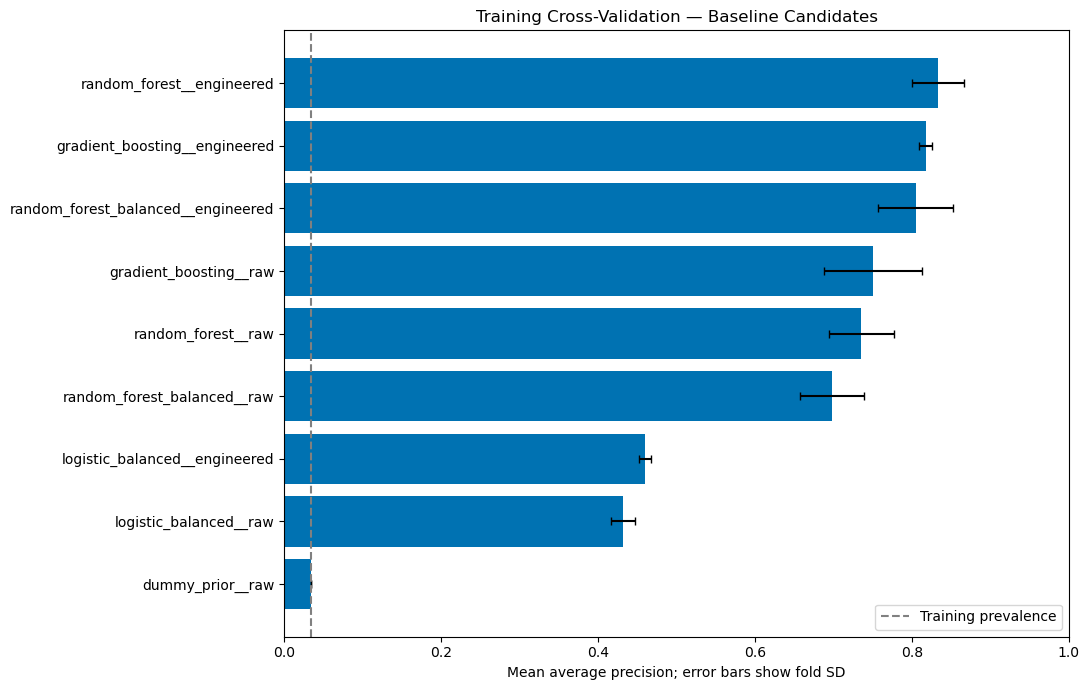

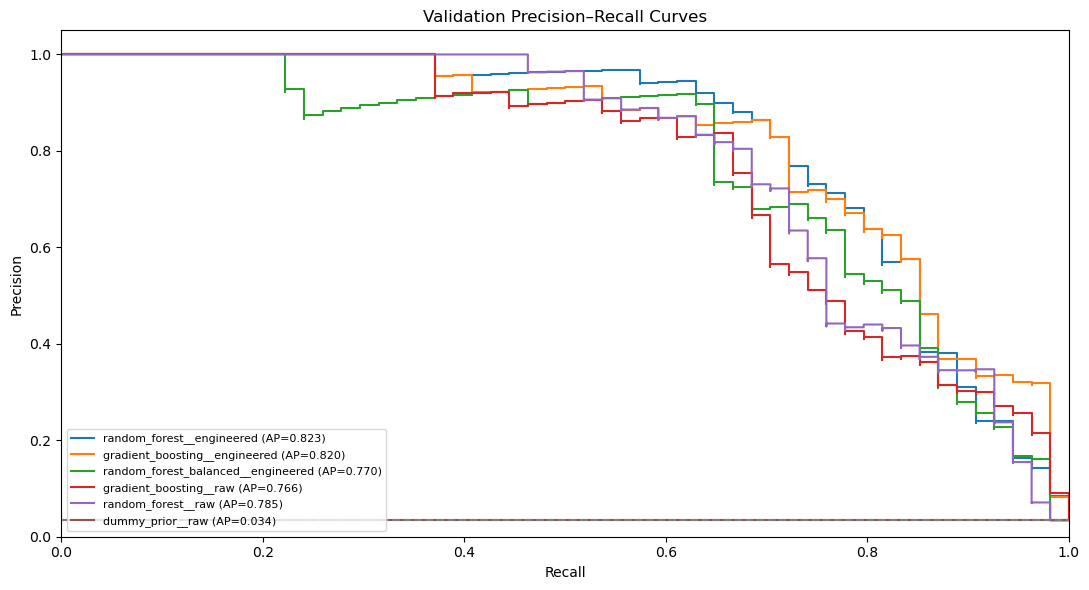

In [8]:
ordered = cv_results.sort_values("average_precision_mean")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(
    ordered.index, ordered["average_precision_mean"],
    xerr=ordered["average_precision_std"], color="#0072B2", capsize=3,
)
ax.axvline(y_train.mean(), color="gray", linestyle="--", label="Training prevalence")
ax.set_xlabel("Mean average precision; error bars show fold SD")
ax.set_xlim(0, 1)
ax.set_title("Training Cross-Validation — Baseline Candidates")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "training_cv_average_precision.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

curve_ids = list(ranked_substantive.head(5).index) + [dummy_id]
fig, ax = plt.subplots(figsize=(11, 6))
for candidate_id in curve_ids:
    precision_values, recall_values, _ = precision_recall_curve(
        y_validation, validation_scores[candidate_id],
    )
    ap = validation_results.loc[candidate_id, "average_precision"]
    ax.step(
        recall_values, precision_values, where="post",
        label=f"{candidate_id} (AP={ap:.3f})",
    )
ax.axhline(y_validation.mean(), color="gray", linestyle="--")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_title("Validation Precision–Recall Curves")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "validation_precision_recall_curves.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 9. Explore thresholds using validation data

I keep 0.5 as the initial reference and calculate a **maximum-validation-F1** cutoff as a reproducible demonstration. F1 balances precision and recall, but does not encode maintenance costs.

I also show cutoffs with the highest observed precision among those meeting illustrative validation recall levels of 80%, 90%, and 95%. These levels are scenarios, not assumed business requirements or guarantees on new data.

The last precision–recall endpoint has no corresponding threshold, so I exclude it before selecting cutoffs. All selected thresholds use validation data only. Scores reported at a validation-selected cutoff are tuning results, not an independent performance estimate.


In [9]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation, selected_scores,
)
threshold_grid = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1],
})
denominator = threshold_grid["precision"] + threshold_grid["recall"]
threshold_grid["f1"] = np.divide(
    2 * threshold_grid["precision"] * threshold_grid["recall"],
    denominator, out=np.zeros(len(threshold_grid)), where=denominator.to_numpy() > 0,
)
best_f1_row = threshold_grid.sort_values(
    ["f1", "threshold"], ascending=[False, False], kind="stable",
).iloc[0]
demo_threshold = float(best_f1_row["threshold"])

threshold_profiles = [{
    "profile": "default_0.5", "recall_target": np.nan,
    **score_metrics(y_validation, selected_scores, DEFAULT_THRESHOLD),
}, {
    "profile": "maximum_validation_F1", "recall_target": np.nan,
    **score_metrics(y_validation, selected_scores, demo_threshold),
}]

for target_recall in RECALL_SCENARIOS:
    feasible = threshold_grid.loc[threshold_grid["recall"] >= target_recall]
    if feasible.empty:
        raise RuntimeError(f"No threshold met recall scenario {target_recall}.")
    chosen = feasible.sort_values(
        ["precision", "threshold"], ascending=[False, False], kind="stable",
    ).iloc[0]
    metrics = score_metrics(y_validation, selected_scores, float(chosen["threshold"]))
    if metrics["recall"] + 1e-12 < target_recall:
        raise RuntimeError("The selected threshold failed its measured recall constraint.")
    threshold_profiles.append({
        "profile": f"recall_at_least_{target_recall:.0%}",
        "recall_target": target_recall, **metrics,
    })

threshold_results = pd.DataFrame(threshold_profiles).set_index("profile")
display(threshold_results.round(4))
print(f"Selected candidate: {selected_id}")
print(f"Demonstration cutoff maximizing validation F1: {demo_threshold:.6f}")
print("A deployment cutoff still requires an explicit operating objective and independent evaluation.")


Selected candidate: random_forest__engineered
Demonstration cutoff maximizing validation F1: 0.343709
A deployment cutoff still requires an explicit operating objective and independent evaluation.


,recall_target,threshold,average_precision,roc_auc,precision,recall,f1,accuracy,true_positives,false_negatives,false_positives,true_negatives
profile,,,,,,,,,,,,
default_0.5,NaN,0.5000,0.8228,0.977,0.9412,0.5926,0.7273,0.9850,32,22,2,1544
maximum_validation_F1,NaN,0.3437,0.8228,0.977,0.8636,0.7037,0.7755,0.9862,38,16,6,1540
recall_at_least_80%,0.80,0.1534,0.8228,0.977,0.6377,0.8148,0.7154,0.9781,44,10,25,1521
recall_at_least_90%,0.90,0.0518,0.8228,0.977,0.3101,0.9074,0.4623,0.9288,49,5,109,1437
recall_at_least_95%,0.95,0.0120,0.8228,0.977,0.1625,0.9630,0.2781,0.8312,52,2,268,1278


## 10. Examine the selected model's decisions

I compare the 0.5 reference with the maximum-validation-F1 demonstration cutoff. The classification report and matrices describe these same validation observations; they do not establish performance on the reserved test set.


              precision    recall  f1-score   support

  No failure       0.99      1.00      0.99      1546
     Failure       0.86      0.70      0.78        54

    accuracy                           0.99      1600
   macro avg       0.93      0.85      0.88      1600
weighted avg       0.99      0.99      0.99      1600



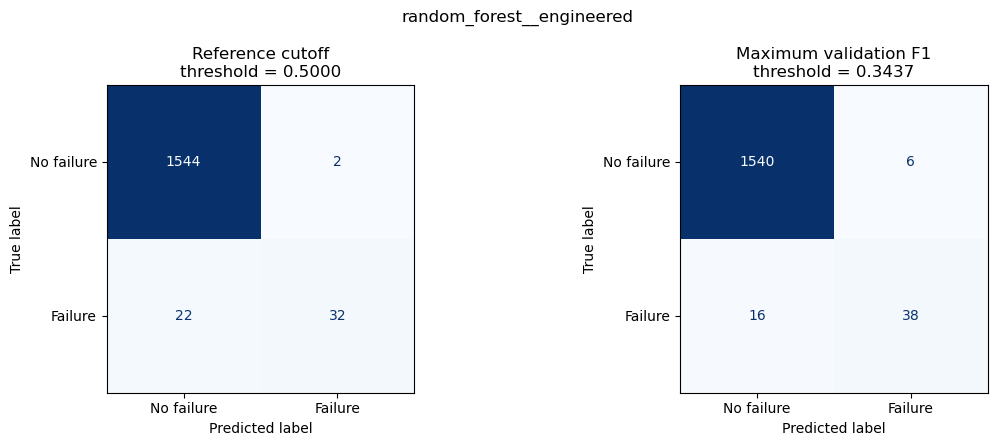

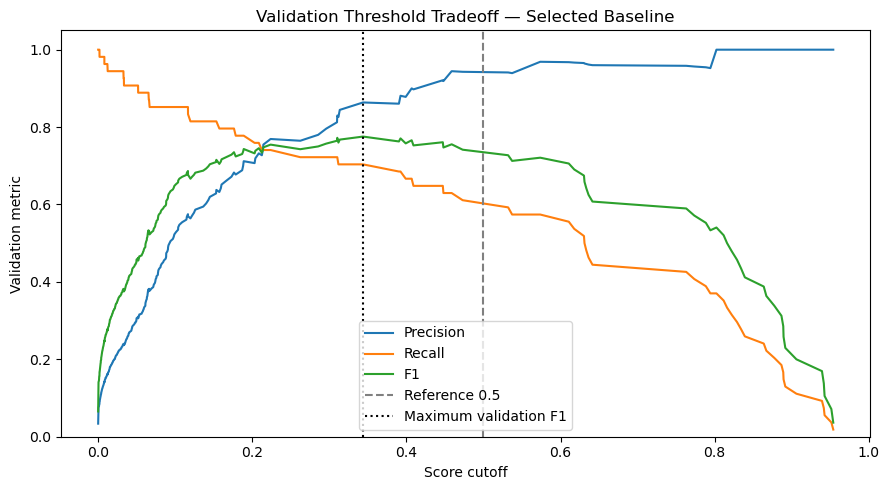

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (label, threshold) in zip(axes, [
    ("Reference cutoff", DEFAULT_THRESHOLD),
    ("Maximum validation F1", demo_threshold),
]):
    predictions = (selected_scores >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_validation, predictions, labels=[0, 1],
        display_labels=["No failure", "Failure"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(f"{label}\nthreshold = {threshold:.4f}")
fig.suptitle(selected_id)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "selected_model_threshold_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print(classification_report(
    y_validation, (selected_scores >= demo_threshold).astype(int),
    labels=[0, 1], target_names=["No failure", "Failure"], zero_division=0,
))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(threshold_grid["threshold"], threshold_grid["precision"], label="Precision")
ax.plot(threshold_grid["threshold"], threshold_grid["recall"], label="Recall")
ax.plot(threshold_grid["threshold"], threshold_grid["f1"], label="F1")
ax.axvline(DEFAULT_THRESHOLD, color="gray", linestyle="--", label="Reference 0.5")
ax.axvline(demo_threshold, color="black", linestyle=":", label="Maximum validation F1")
ax.set_xlabel("Score cutoff")
ax.set_ylabel("Validation metric")
ax.set_ylim(0, 1.05)
ax.set_title("Validation Threshold Tradeoff — Selected Baseline")
ax.legend()
plt.tight_layout()
plt.savefig(VISUALS_DIR / "validation_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 11. Save the provisional model and reports

I save the selected pipeline as fitted on the training set, together with an input schema and threshold metadata. I do **not** refit it on combined training and validation rows here, because that would change the model after selecting its validation cutoff.

The serialized pipeline contains fitted preprocessing and the classifier. Row-wise engineered feature formulas are applied by `prepare_features` **before** calling it; the input schema records the required columns and formulas. The reload example below demonstrates the complete preparation step.

No custom `src` modules are required. I record package versions for reproducibility. Reference: [model persistence](https://scikit-learn.org/stable/model_persistence.html).


In [11]:
MODEL_PATH = MODELS_DIR / "selected_baseline.joblib"
SCHEMA_PATH = MODELS_DIR / "input_schema.json"
METADATA_PATH = MODELS_DIR / "model_metadata.json"

input_schema = {
    "raw_input_columns": RAW_FEATURES,
    "feature_set": selected_feature_set,
    "model_input_columns": FEATURE_SETS[selected_feature_set],
    "valid_Type_values": ["L", "M", "H"],
    "feature_preparation_required_before_pipeline": True,
    "engineered_formulas": {
        "Temp_diff": "Process temperature [K] - Air temperature [K]",
        "Torque_RPM_ratio": "Torque [Nm] / (Rotational speed [rpm] + 1)",
    } if selected_feature_set == "engineered" else {},
}
model_metadata = {
    "candidate": selected_id,
    "feature_set": selected_feature_set,
    "selected_by": "Highest mean average precision in training-only shared 3-fold stratified CV",
    "training_rows": int(len(train_df)),
    "validation_rows": int(len(validation_df)),
    "reserved_final_test_rows": int(len(final_test_udi)),
    "final_test_scored": False,
    "early_EDA_included_final_test_rows": True,
    "model_refitted_on_validation": False,
    "provisional": True,
    "calibration_established": False,
    "demonstration_threshold": demo_threshold,
    "threshold_selection": "Maximum validation F1; not a specified maintenance-cost optimum",
    "reference_threshold": DEFAULT_THRESHOLD,
    "validation_AP": float(validation_results.loc[selected_id, "average_precision"]),
    "training_CV_AP_mean": float(cv_results.loc[selected_id, "average_precision_mean"]),
    "training_CV_AP_std": float(cv_results.loc[selected_id, "average_precision_std"]),
    "input_checksums": input_checksums,
    "seed": SEED,
    "cv_splits": CV_SPLITS,
    "class_balancing": "Candidate-specific class weighting; no resampling",
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "scipy": scipy.__version__, "joblib": joblib.__version__,
    },
}

joblib.dump(selected_model, MODEL_PATH)
SCHEMA_PATH.write_text(json.dumps(input_schema, indent=2, allow_nan=False), encoding="utf-8")
METADATA_PATH.write_text(json.dumps(model_metadata, indent=2, allow_nan=False), encoding="utf-8")

cv_results.to_csv(REPORTS_DIR / "cross_validation_results.csv")
cv_fold_results.to_csv(REPORTS_DIR / "cross_validation_folds.csv", index=False)
training_fold_manifest.to_csv(REPORTS_DIR / "training_cv_fold_manifest.csv", index=False)
validation_results.to_csv(REPORTS_DIR / "validation_results.csv")
feature_comparison.to_csv(REPORTS_DIR / "feature_engineering_comparison.csv")
threshold_results.to_csv(REPORTS_DIR / "threshold_profiles.csv")
threshold_grid.to_csv(REPORTS_DIR / "selected_model_threshold_grid.csv", index=False)
split_summary.to_csv(REPORTS_DIR / "split_summary.csv")

validation_prediction_table = pd.DataFrame({
    "UDI": validation_df["UDI"],
    "Machine failure": y_validation,
})
for candidate_id, scores in validation_scores.items():
    validation_prediction_table[f"score__{candidate_id}"] = scores
validation_prediction_table.to_csv(REPORTS_DIR / "validation_predictions.csv", index=False)

selected_prediction_table = validation_df[["UDI", *RAW_FEATURES, "Machine failure"]].copy()
selected_prediction_table["failure_score"] = selected_scores
selected_prediction_table["prediction_at_0.5"] = (selected_scores >= DEFAULT_THRESHOLD).astype(int)
selected_prediction_table["prediction_at_demo_threshold"] = (selected_scores >= demo_threshold).astype(int)
selected_prediction_table.to_csv(REPORTS_DIR / "selected_validation_predictions.csv", index=False)

candidate_parameters = {
    candidate_id: {
        **candidate_metadata[candidate_id],
        "estimator": candidate.named_steps["classifier"].__class__.__name__,
        "estimator_parameters": candidate.named_steps["classifier"].get_params(),
    }
    for candidate_id, candidate in candidates.items()
}
(REPORTS_DIR / "experiment_settings.json").write_text(
    json.dumps({
        "model_metadata": model_metadata,
        "candidate_settings": candidate_parameters,
        "feature_sets": FEATURE_SETS,
        "recall_scenarios": RECALL_SCENARIOS,
        "selection_metric": "training_cross_validation_average_precision_mean",
    }, indent=2, allow_nan=False), encoding="utf-8",
)
print(f"Saved provisional model: {MODEL_PATH.relative_to(PROJECT_ROOT)}")
print(f"Saved reports: {REPORTS_DIR.relative_to(PROJECT_ROOT)}")


Saved provisional model: models\baseline\selected_baseline.joblib
Saved reports: reports\baseline


## 12. Reload and check the saved model

I reload the pipeline and schema, rebuild the selected feature matrix from raw validation inputs, and check that its scores match those produced before saving. I use the demonstration cutoff only to illustrate the complete prediction workflow.


In [12]:
reloaded_model = joblib.load(MODEL_PATH)
reloaded_schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
reloaded_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))

prepared_validation = prepare_features(validation_df, reloaded_schema["feature_set"])
if prepared_validation.columns.tolist() != reloaded_schema["model_input_columns"]:
    raise ValueError("Prepared feature columns do not match the saved schema.")
reloaded_scores = positive_scores(reloaded_model, prepared_validation)
np.testing.assert_allclose(reloaded_scores, selected_scores, rtol=0, atol=1e-12)

example = validation_df[["UDI", *RAW_FEATURES]].head(5).copy()
example_scores = positive_scores(
    reloaded_model, prepare_features(example, reloaded_schema["feature_set"]),
)
example["failure_score"] = example_scores
example["demo_prediction"] = (
    example_scores >= reloaded_metadata["demonstration_threshold"]
).astype(int)
display(example)

for path in [DATA_PATH, MANIFEST_PATH, SMOTE_SETTINGS_PATH]:
    if sha256(path) != input_checksums[path.name]:
        raise RuntimeError(f"Input file changed during the run: {path.name}")

print("Verified: saved-model scores match, and all input files are unchanged.")
print("Final-test observations were not scored.")


Verified: saved-model scores match, and all input files are unchanged.
Final-test observations were not scored.


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,failure_score,demo_prediction
0,8,298.1,308.6,1527,40.2,16,L,0.0,0
1,11,298.4,308.9,1782,23.9,24,H,0.0,0
2,15,298.6,309.2,2035,19.6,40,L,0.0,0
3,29,299.1,309.4,1439,44.2,82,L,0.0,0
4,34,298.9,309.3,1665,32.5,93,L,0.0,0


## Interpretation and next steps

I have established a measured baseline across linear and tree models, assessed two feature formulas, and recorded threshold tradeoffs. The outputs describe development performance and tuning choices, not a validated deployment system.

Next, I compare additional models and ensembles using the saved split and training fold assignments. I will assess calibration and choose an operating objective before assigning operational risk tiers. H3 remains pending until the specified ensemble comparison is completed.

The final test set stays unscored until the model-selection process is complete, with the earlier EDA exposure acknowledged when reporting its results.
